# IEEE 37-bus modified ERCOT sequential DDPG switching-cost beta matrix

## Purpose

The `band` reward stays fixed at `abs` alpha `0.1`; the cells differ only in beta.
The saved beta `1e-5` cell is the benchmark row.
Each cell's combined cost uses its own beta and is not comparable across cells.
Loads follow measured ERCOT hourly loads from the saved archive splits. Results describe this saved validation split.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().parents[1]
if not (ROOT / "src/feeder").is_dir():
    raise RuntimeError("Start the kernel in the notebook directory (experiments/<feeder>/).")
sys.path.insert(0, str(ROOT / "src"))

from common.beta_matrix import (
    run_beta_matrix,
    show_beta_matrix,
    show_beta_matrix_conclusions,
    show_beta_matrix_training,
)

print("Repository root resolved.")

Repository root resolved.


## Parameters

Edit this cell, then restart the kernel and run all cells.
`MODE` selects training, evaluation, or viewing saved results.
Make sure `OVERWRITE` stays false when viewing saved results.

In [2]:
FEEDER = "ieee37mod"  # Named feeder.
DATASET = "ieee37mod-ercot"  # Named dataset.
SEEDS = [0, 1, 2]  # Independent training seeds.
MODE = "view"  # Read saved results.
OVERWRITE = False  # Protect existing outputs.
TRAINING_DAYS = 7985  # Complete training days per run.
SPLIT = "validation"  # Evaluation split.
EVALUATION_DAYS = None  # Evaluate the complete split.
DEVIATION = "abs"  # Absolute voltage deviation.
ALPHA = 0.1  # Deviation weight in the reward.
RATE = 20.0  # Recorded deviation rate.
BENCHMARK_BETA = 1e-5  # Saved benchmark cell.
CELLS = [  # Switching-cost beta, run name before _seed<seed>.
    (1e-3, "band_b0.001_abs_a0.1"),
    (1e-5, "band_b1e-05_abs_a0.1"),
    (1e-7, "band_b1e-07_abs_a0.1"),
]
PLOT_DAY = 280  # Selected evaluated day by zero-based position.

**Units and interfaces.** Alpha weights mean absolute voltage deviation from 1 p.u.; beta weights executed tap steps.
Physical voltage metrics share their definitions across cells.
Each cell's combined cost uses its own beta.
Do not rank cells by combined cost.

In [3]:
BASE = {
    "protocol": "sequential",
    "algorithm": "ddpg",
    "feeder": FEEDER,
    "dataset": DATASET,
    "seeds": SEEDS,
    "mode": MODE,
    "overwrite": OVERWRITE,
    "training_days": TRAINING_DAYS,
    "reward": "band",
    "deviation": DEVIATION,
    "alpha": ALPHA,
    "rate": RATE,
    "split": SPLIT,
    "evaluation_days": EVALUATION_DAYS,
    "plot_day": PLOT_DAY,
    "show_hourly_details": False,
    "root": ROOT,
}
cells = run_beta_matrix(BASE, CELLS)

Cell band_b0.001_abs_a0.1: reward band {'beta': 0.001, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee37mod-ercot/seq_ddpg/band_b0.001_abs_a0.1_seed0/, results/ieee37mod-ercot/seq_ddpg/band_b0.001_abs_a0.1_seed1/, results/ieee37mod-ercot/seq_ddpg/band_b0.001_abs_a0.1_seed2/
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.


Day and hour alignment passed for 636 days, 15264 hours, and 5 methods.
Cell band_b1e-05_abs_a0.1: reward band {'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee37mod-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed0/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed1/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed2/
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.


Day and hour alignment passed for 636 days, 15264 hours, and 5 methods.
Cell band_b1e-07_abs_a0.1: reward band {'beta': 1e-07, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee37mod-ercot/seq_ddpg/band_b1e-07_abs_a0.1_seed0/, results/ieee37mod-ercot/seq_ddpg/band_b1e-07_abs_a0.1_seed1/, results/ieee37mod-ercot/seq_ddpg/band_b1e-07_abs_a0.1_seed2/
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.


Day and hour alignment passed for 636 days, 15264 hours, and 5 methods.
Beta matrix identity passed: dataset, split, protocol, algorithm, seeds, and days match.


## Training records

These records cover all three beta cells, including the saved beta `1e-5` benchmark.
Each curve averages the selected seeds before smoothing.
The panels show training voltage cost and tap steps per day.

Cost includes exploration and does not represent held-out performance or prove convergence.

Run,Reward,Reward parameters,Benchmark beta,Layer sizes,Completed training days,Update counts
DDPG seed 0,band,"{'beta': 0.001, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",0.001,"[400, 300]",7985,unavailable
DDPG seed 1,band,"{'beta': 0.001, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",0.001,"[400, 300]",7985,unavailable
DDPG seed 2,band,"{'beta': 0.001, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",0.001,"[400, 300]",7985,unavailable


Run,Reward,Reward parameters,Benchmark beta,Layer sizes,Completed training days,Update counts
DDPG seed 0,band,"{'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-05,"[400, 300]",7985,unavailable
DDPG seed 1,band,"{'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-05,"[400, 300]",7985,unavailable
DDPG seed 2,band,"{'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-05,"[400, 300]",7985,unavailable


Run,Reward,Reward parameters,Benchmark beta,Layer sizes,Completed training days,Update counts
DDPG seed 0,band,"{'beta': 1e-07, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-07,"[400, 300]",7985,unavailable
DDPG seed 1,band,"{'beta': 1e-07, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-07,"[400, 300]",7985,unavailable
DDPG seed 2,band,"{'beta': 1e-07, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-07,"[400, 300]",7985,unavailable


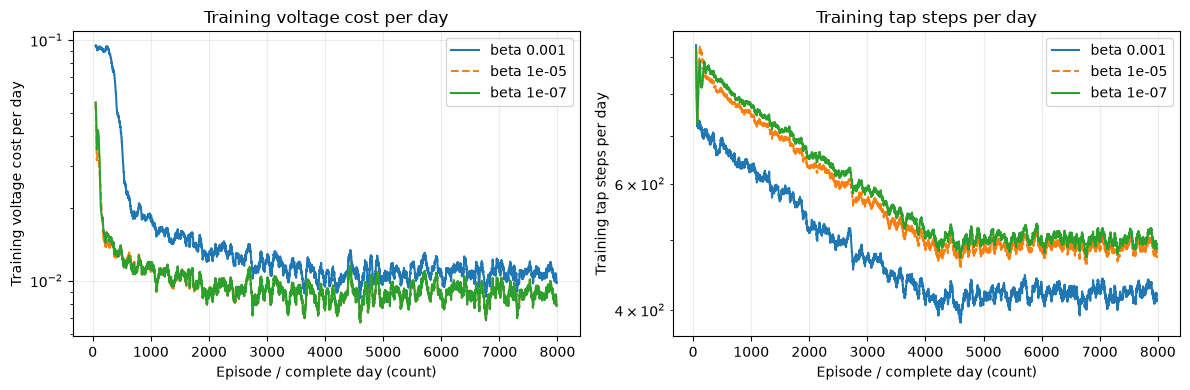

Cost uses the fixed evaluation metric on training episodes and includes exploration. It is not held-out performance or proof of convergence.

In [4]:
show_beta_matrix_training(cells);

## Switching-cost beta matrix

Each row reports the seed mean ± sample standard deviation of per-run metrics.
Paired differences match seeds and inputs; spread across three seeds is not a confidence interval.
Combined cost uses each cell's own beta and is not comparable across cells.
Feasible hours require every live node inside [0.95, 1.05] p.u.

The trade-off figure shows individual runs and cell seed means.
The distributions pool all evaluated days across seeds.

The selected day follows measured ERCOT hourly loads, normalised by the calendar-year peak.

Cell,Mean daily voltage cost
beta 0.001,1.49772e-03 ± 2.54379e-03
beta 1e-05,3.79083e-05 ± 1.74707e-06
beta 1e-07,3.97645e-05 ± 2.54004e-06


Cell,Mean absolute deviation (p.u.)
beta 0.001,1.6993e-02 ± 7.0035e-03
beta 1e-05,7.3774e-03 ± 2.5825e-04
beta 1e-07,7.3442e-03 ± 7.1241e-05


Cell,Mean tap steps/day
beta 0.001,41.503 ± 12.500
beta 1e-05,78.571 ± 18.509
beta 1e-07,86.270 ± 7.885


Cell,Feasible hours (%)
beta 0.001,24.7 ± 24.3
beta 1e-05,37.4 ± 7.2
beta 1e-07,33.8 ± 5.8


Cell,Mean daily combined cost,Mean daily switching cost
beta 0.001,4.30003e-02 ± 1.44907e-02,4.15026e-02 ± 1.25001e-02
beta 1e-05,8.23621e-04 ± 1.86835e-04,7.85713e-04 ± 1.85089e-04
beta 1e-07,4.83915e-05 ± 1.93932e-06,8.62704e-06 ± 7.88528e-07


Cell,Mean daily voltage cost
beta 0.001,1.45981e-03 ± 2.54474e-03
beta 1e-07,1.85621e-06 ± 7.97009e-07


Cell,Mean absolute deviation (p.u.)
beta 0.001,9.6157e-03 ± 6.9482e-03
beta 1e-07,-3.3200e-05 ± 2.8519e-04


Cell,Mean tap steps/day
beta 0.001,-37.069 ± 30.658
beta 1e-07,7.699 ± 25.430


Selected day: 2024-10-08


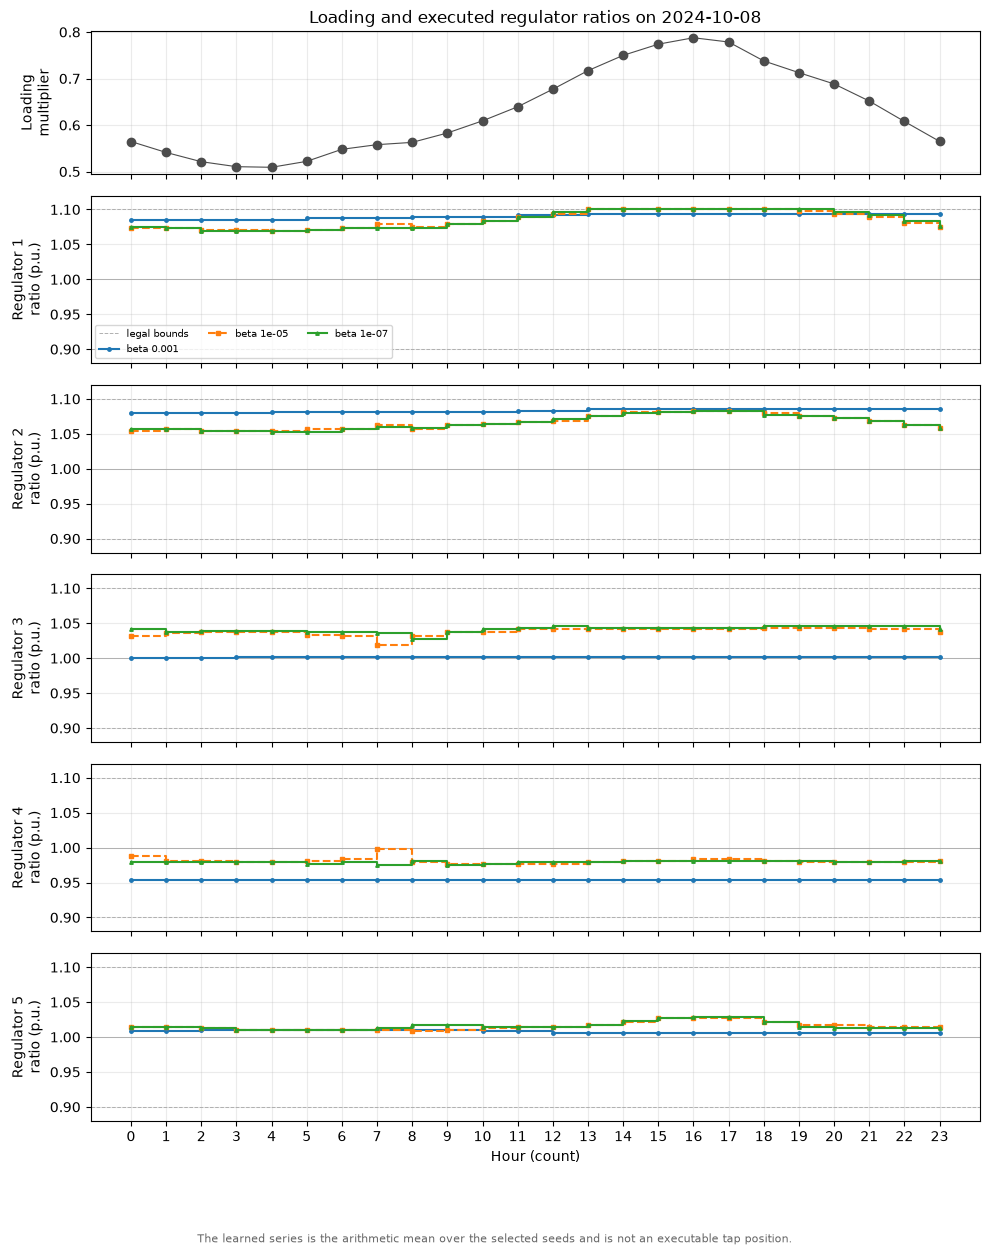

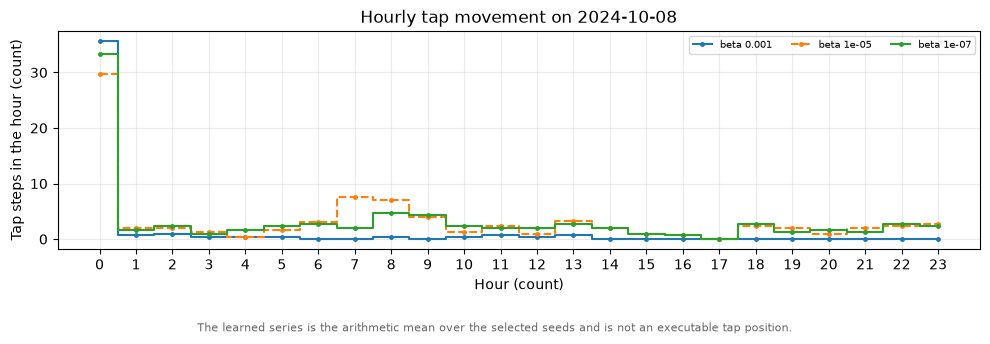

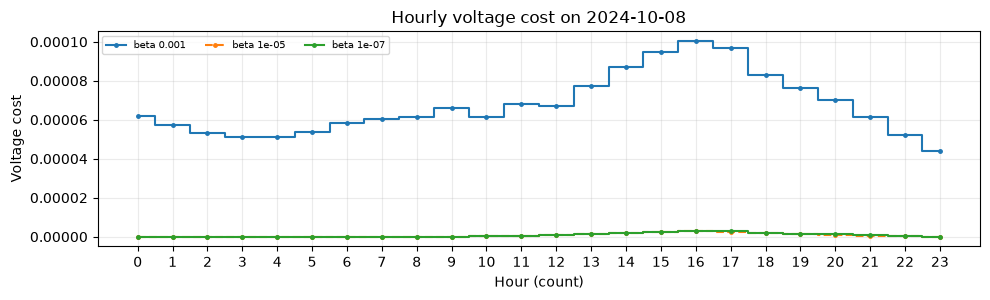

The learned series is the arithmetic mean over the selected seeds and is not an executable tap position.

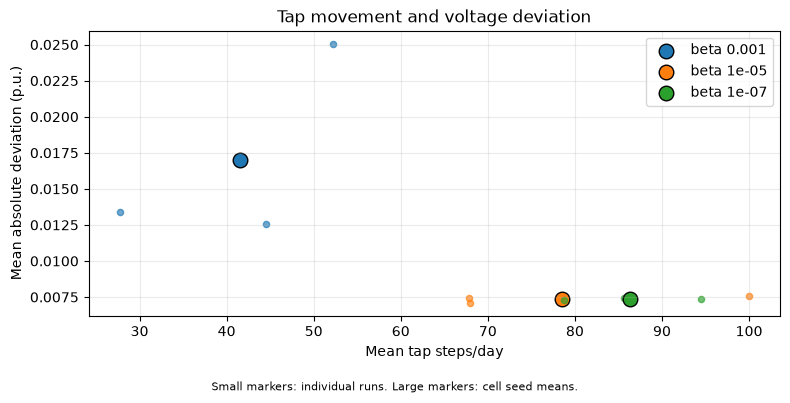

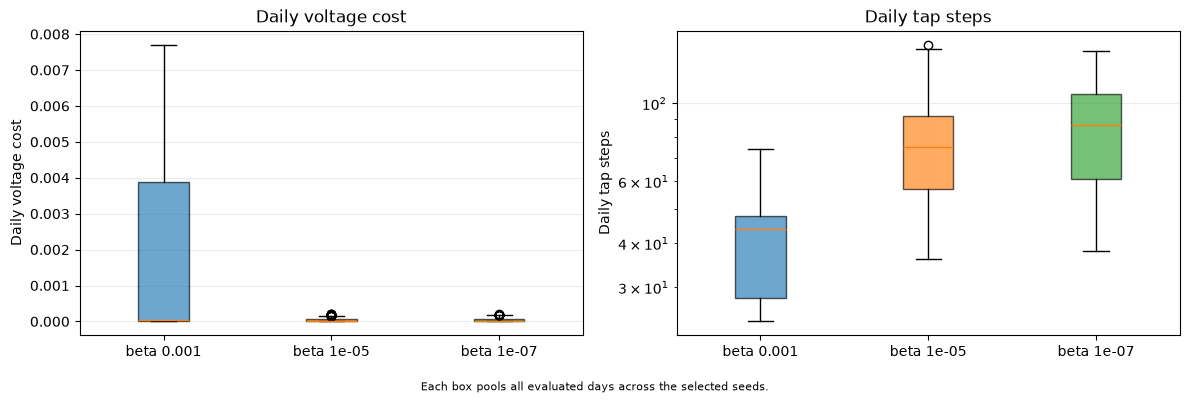

In [5]:
show_beta_matrix(cells, BENCHMARK_BETA);

## Final answers

In [6]:
show_beta_matrix_conclusions(cells, BENCHMARK_BETA)

Mean daily voltage cost: the beta 1e-05 benchmark cell has seed mean 3.79083e-05; the lowest seed mean is 3.79083e-05 for beta 1e-05.

Mean absolute deviation (p.u.): the beta 1e-05 benchmark cell has seed mean 7.3774e-03; the lowest seed mean is 7.3442e-03 for beta 1e-07.

Mean tap steps/day: the beta 1e-05 benchmark cell has seed mean 78.571; the lowest seed mean is 41.503 for beta 0.001.

Feasible hours (%): the beta 1e-05 benchmark cell has seed mean 37.4; the highest seed mean is 37.4 for beta 1e-05.

Mean tap steps/day: seed means strictly decrease as beta increases: yes. This holds on every seed individually: no.

Mean absolute deviation (p.u.): seed means strictly increase as beta increases: yes. This holds on every seed individually: no.

These statements describe the saved validation split and these dataset inputs only.